In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("Environnement prêt")
print("Pandas :", pd.__version__)
print("Scikit-learn :", sklearn.__version__)

Environnement prêt
Pandas : 2.3.3
Scikit-learn : 1.7.2


In [2]:
from pathlib import Path

train_path = Path("../data/KDDTrain+.txt")
test_path = Path("../data/KDDTest+.txt")

print("Train existe :", train_path.exists())
print("Test existe  :", test_path.exists())

Train existe : True
Test existe  : True


In [3]:
columns = [
    "duration",
    "protocol_type",
    "service",
    "flag",
    "src_bytes",
    "dst_bytes",
    "land",
    "wrong_fragment",
    "urgent",
    "hot",
    "num_failed_logins",
    "logged_in",
    "num_compromised",
    "root_shell",
    "su_attempted",
    "num_root",
    "num_file_creations",
    "num_shells",
    "num_access_files",
    "num_outbound_cmds",
    "is_host_login",
    "is_guest_login",
    "count",
    "srv_count",
    "serror_rate",
    "srv_serror_rate",
    "rerror_rate",
    "srv_rerror_rate",
    "same_srv_rate",
    "diff_srv_rate",
    "srv_diff_host_rate",
    "dst_host_count",
    "dst_host_srv_count",
    "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate",
    "dst_host_srv_serror_rate",
    "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate",
    "label",
    "difficulty"
]

print("Nombre de colonnes :", len(columns))

Nombre de colonnes : 43


In [4]:
train_df = pd.read_csv(
    train_path,
    names=columns,
    header=None
)

test_df = pd.read_csv(
    test_path,
    names=columns,
    header=None
)

print("Dimensions entraînement :", train_df.shape)
print("Dimensions test :", test_df.shape)

Dimensions entraînement : (125973, 43)
Dimensions test : (22544, 43)


In [5]:
train_df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [6]:
train_df["label"].value_counts().head(15)

label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
Name: count, dtype: int64

In [7]:
train_df["binary_label"] = train_df["label"].apply(
    lambda value: "normal" if value == "normal" else "attack"
)

test_df["binary_label"] = test_df["label"].apply(
    lambda value: "normal" if value == "normal" else "attack"
)

print(train_df["binary_label"].value_counts())

binary_label
normal    67343
attack    58630
Name: count, dtype: int64


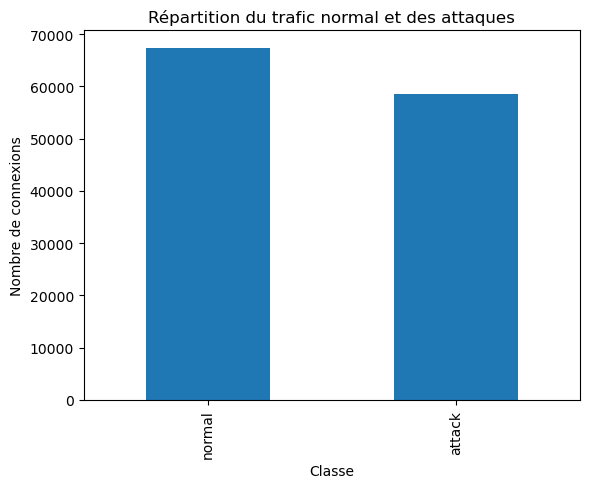

In [8]:
train_df["binary_label"].value_counts().plot(
    kind="bar",
    title="Répartition du trafic normal et des attaques"
)

plt.xlabel("Classe")
plt.ylabel("Nombre de connexions")
plt.show()

In [9]:
X_train = train_df.drop(
    columns=["label", "difficulty", "binary_label"]
)

X_test = test_df.drop(
    columns=["label", "difficulty", "binary_label"]
)
y_train = train_df["binary_label"].map({
    "normal": 0,
    "attack": 1
})

y_test = test_df["binary_label"].map({
    "normal": 0,
    "attack": 1
})

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (125973, 41)
X_test  : (22544, 41)
y_train : (125973,)
y_test  : (22544,)


In [10]:
categorical_columns = [
    "protocol_type",
    "service",
    "flag"
]

numeric_columns = [
    column
    for column in X_train.columns
    if column not in categorical_columns
]

print("Colonnes catégorielles :", categorical_columns)
print("Nombre de colonnes numériques :", len(numeric_columns))

Colonnes catégorielles : ['protocol_type', 'service', 'flag']
Nombre de colonnes numériques : 38


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ]
)

print("Pipeline créé avec succès")

Pipeline créé avec succès


In [12]:
pipeline.fit(X_train, y_train)

print("Entraînement terminé")

Entraînement terminé


In [13]:
y_pred = pipeline.predict(X_test)

print("Prédictions terminées")

Prédictions terminées


In [14]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy :", round(accuracy, 4))
print()
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Attaque"]
    )
)

Accuracy : 0.7784

              precision    recall  f1-score   support

      Normal       0.67      0.97      0.79      9711
     Attaque       0.97      0.63      0.76     12833

    accuracy                           0.78     22544
   macro avg       0.82      0.80      0.78     22544
weighted avg       0.84      0.78      0.78     22544



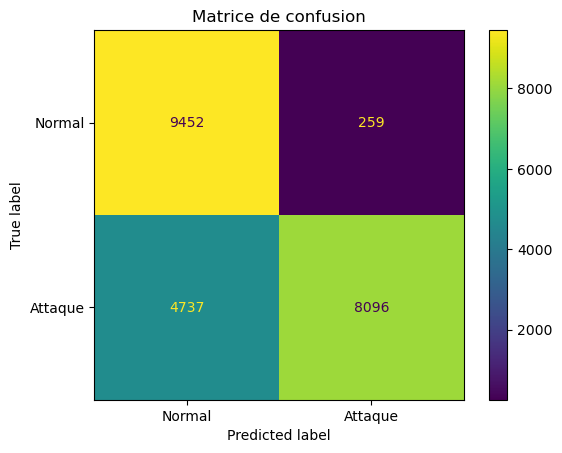

In [15]:
matrix = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=["Normal", "Attaque"]
)

display.plot()
plt.title("Matrice de confusion")
plt.show()

In [16]:
balanced_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

balanced_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", balanced_model)
    ]
)

balanced_pipeline.fit(X_train, y_train)

y_pred_balanced = balanced_pipeline.predict(X_test)

In [17]:
print(
    classification_report(
        y_test,
        y_pred_balanced,
        target_names=["Normal", "Attaque"]
    )
)

              precision    recall  f1-score   support

      Normal       0.65      0.97      0.78      9711
     Attaque       0.97      0.61      0.75     12833

    accuracy                           0.77     22544
   macro avg       0.81      0.79      0.77     22544
weighted avg       0.83      0.77      0.76     22544



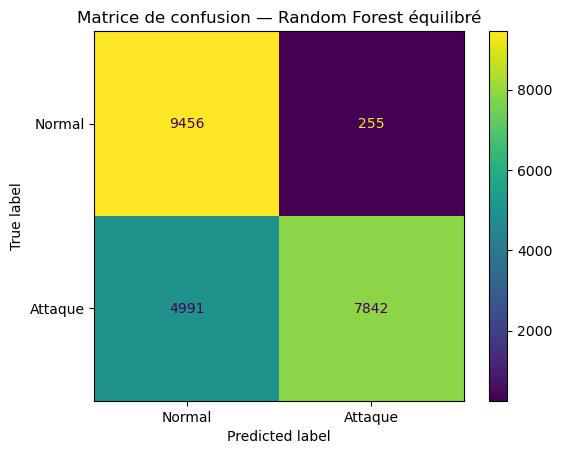

In [18]:
balanced_matrix = confusion_matrix(
    y_test,
    y_pred_balanced
)

balanced_display = ConfusionMatrixDisplay(
    confusion_matrix=balanced_matrix,
    display_labels=["Normal", "Attaque"]
)

balanced_display.plot()
plt.title("Matrice de confusion — Random Forest équilibré")
plt.show()

In [19]:
attack_probabilities = pipeline.predict_proba(X_test)[:, 1]

threshold = 0.30

y_pred_threshold = (
    attack_probabilities >= threshold
).astype(int)

In [20]:
print(
    classification_report(
        y_test,
        y_pred_threshold,
        target_names=["Normal", "Attaque"]
    )
)

              precision    recall  f1-score   support

      Normal       0.72      0.97      0.83      9711
     Attaque       0.97      0.72      0.83     12833

    accuracy                           0.83     22544
   macro avg       0.85      0.84      0.83     22544
weighted avg       0.86      0.83      0.83     22544



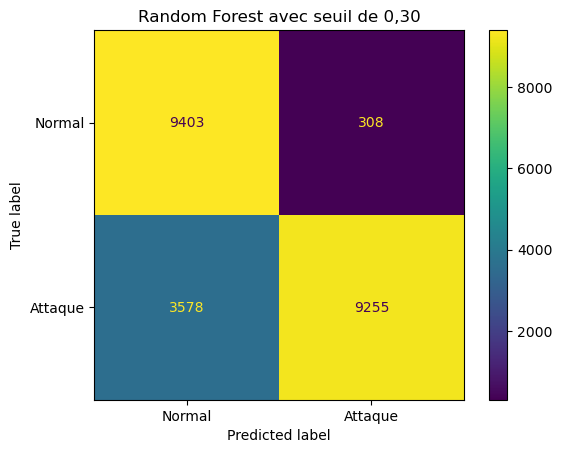

In [21]:
threshold_matrix = confusion_matrix(
    y_test,
    y_pred_threshold
)

threshold_display = ConfusionMatrixDisplay(
    confusion_matrix=threshold_matrix,
    display_labels=["Normal", "Attaque"]
)

threshold_display.plot()
plt.title("Random Forest avec seuil de 0,30")
plt.show()

In [22]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    predictions = (
        attack_probabilities >= threshold
    ).astype(int)

    results.append({
        "seuil": threshold,
        "accuracy": accuracy_score(y_test, predictions),
        "precision_attaque": precision_score(y_test, predictions),
        "recall_attaque": recall_score(y_test, predictions),
        "f1_attaque": f1_score(y_test, predictions)
    })

threshold_results = pd.DataFrame(results)

threshold_results

,seuil,accuracy,precision_attaque,recall_attaque,f1_attaque
0,0.1,0.889017,0.922467,0.878906,0.900160
1,0.2,0.843595,0.935029,0.779397,0.850149
2,0.3,0.827626,0.967793,0.721188,0.826487
3,0.4,0.804383,0.969457,0.677706,0.797744
4,0.5,0.779542,0.968873,0.633055,0.765765
5,0.6,0.764239,0.968703,0.605392,0.745121


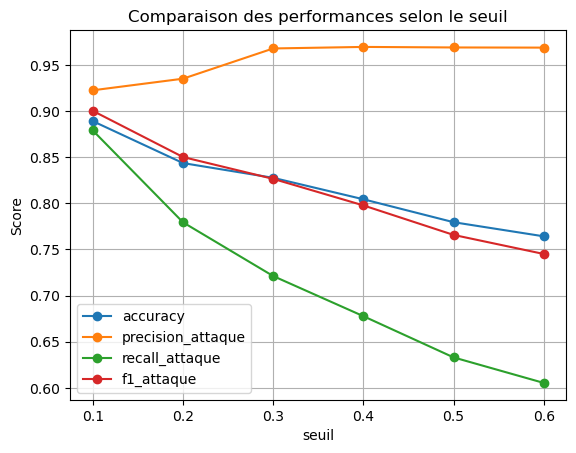

In [23]:
threshold_results.plot(
    x="seuil",
    y=[
        "accuracy",
        "precision_attaque",
        "recall_attaque",
        "f1_attaque"
    ],
    marker="o"
)

plt.title("Comparaison des performances selon le seuil")
plt.ylabel("Score")
plt.grid()
plt.show()

In [24]:
best_threshold = 0.10

y_pred_best = (
    attack_probabilities >= best_threshold
).astype(int)

print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=["Normal", "Attaque"]
    )
)

              precision    recall  f1-score   support

      Normal       0.85      0.90      0.88      9711
     Attaque       0.92      0.88      0.90     12833

    accuracy                           0.89     22544
   macro avg       0.89      0.89      0.89     22544
weighted avg       0.89      0.89      0.89     22544



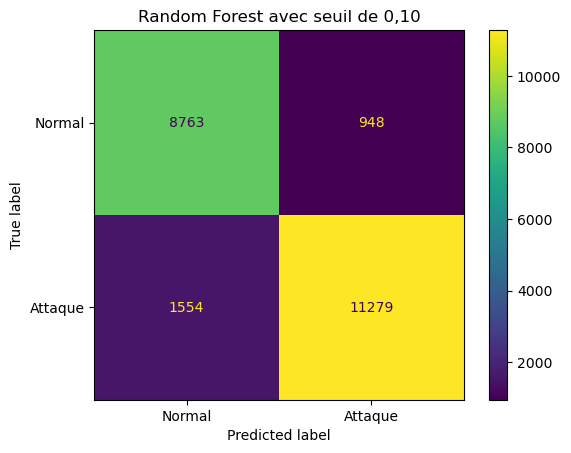

In [25]:
best_matrix = confusion_matrix(
    y_test,
    y_pred_best
)

best_display = ConfusionMatrixDisplay(
    confusion_matrix=best_matrix,
    display_labels=["Normal", "Attaque"]
)

best_display.plot()
plt.title("Random Forest avec seuil de 0,10")
plt.show()

In [26]:
from sklearn.model_selection import train_test_split

X_train_final, X_validation, y_train_final, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Entraînement :", X_train_final.shape)
print("Validation   :", X_validation.shape)
print("Test         :", X_test.shape)

Entraînement : (100778, 41)
Validation   : (25195, 41)
Test         : (22544, 41)


In [27]:
from sklearn.base import clone

final_pipeline = clone(pipeline)

final_pipeline.fit(
    X_train_final,
    y_train_final
)

print("Modèle entraîné")

Modèle entraîné


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

validation_probabilities = final_pipeline.predict_proba(
    X_validation
)[:, 1]

results = []

for threshold in [
    0.05, 0.10, 0.15, 0.20,
    0.25, 0.30, 0.40, 0.50
]:
    validation_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    results.append({
        "seuil": threshold,
        "accuracy": accuracy_score(
            y_validation,
            validation_predictions
        ),
        "precision_attaque": precision_score(
            y_validation,
            validation_predictions
        ),
        "recall_attaque": recall_score(
            y_validation,
            validation_predictions
        ),
        "f1_attaque": f1_score(
            y_validation,
            validation_predictions
        )
    })

validation_results = pd.DataFrame(results)
validation_results

,seuil,accuracy,precision_attaque,recall_attaque,f1_attaque
0,0.05,0.990832,0.980842,0.999829,0.990245
1,0.10,0.995991,0.991710,0.999744,0.995711
2,0.15,0.997301,0.994570,0.999659,0.997108
3,0.20,0.998135,0.996345,0.999659,0.997999
4,0.25,0.998611,0.997447,0.999574,0.998509
5,0.30,0.998690,0.997786,0.999403,0.998594
6,0.40,0.999246,0.999147,0.999232,0.999190
7,0.50,0.999047,0.999488,0.998465,0.998976


In [29]:
best_row = validation_results.loc[
    validation_results["f1_attaque"].idxmax()
]

best_threshold = float(best_row["seuil"])

print("Meilleur seuil :", best_threshold)
print(best_row)

Meilleur seuil : 0.4
seuil                0.400000
accuracy             0.999246
precision_attaque    0.999147
recall_attaque       0.999232
f1_attaque           0.999190
Name: 6, dtype: float64


In [30]:
final_pipeline.fit(
    X_train,
    y_train
)

print("Modèle final entraîné")

Modèle final entraîné


In [31]:
test_probabilities = final_pipeline.predict_proba(
    X_test
)[:, 1]

final_predictions = (
    test_probabilities >= best_threshold
).astype(int)

In [32]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["Normal", "Attaque"]
    )
)

              precision    recall  f1-score   support

      Normal       0.70      0.97      0.81      9711
     Attaque       0.97      0.68      0.80     12833

    accuracy                           0.80     22544
   macro avg       0.83      0.82      0.80     22544
weighted avg       0.85      0.80      0.80     22544



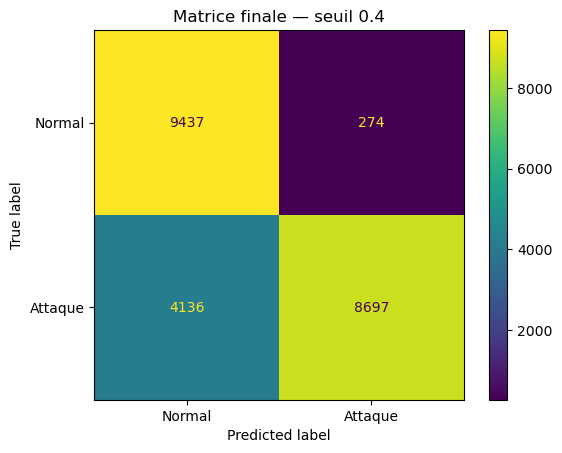

In [33]:
final_matrix = confusion_matrix(
    y_test,
    final_predictions
)

final_display = ConfusionMatrixDisplay(
    confusion_matrix=final_matrix,
    display_labels=["Normal", "Attaque"]
)

final_display.plot()
plt.title(
    f"Matrice finale — seuil {best_threshold}"
)
plt.show()

In [34]:
safe_results = validation_results[
    validation_results["recall_attaque"] >= 0.90
]

if not safe_results.empty:
    best_safe_row = safe_results.loc[
        safe_results["precision_attaque"].idxmax()
    ]

    security_threshold = float(
        best_safe_row["seuil"]
    )

    print("Seuil de sécurité :", security_threshold)
    print(best_safe_row)
else:
    print("Aucun seuil ne donne un rappel supérieur ou égal à 90 %")

Seuil de sécurité : 0.5
seuil                0.500000
accuracy             0.999047
precision_attaque    0.999488
recall_attaque       0.998465
f1_attaque           0.998976
Name: 7, dtype: float64


In [35]:
security_predictions = (
    test_probabilities >= security_threshold
).astype(int)

print(
    classification_report(
        y_test,
        security_predictions,
        target_names=["Normal", "Attaque"]
    )
)

              precision    recall  f1-score   support

      Normal       0.67      0.97      0.79      9711
     Attaque       0.97      0.63      0.77     12833

    accuracy                           0.78     22544
   macro avg       0.82      0.80      0.78     22544
weighted avg       0.84      0.78      0.78     22544



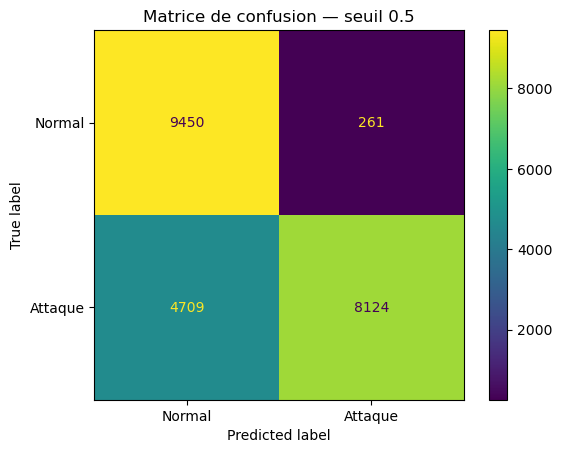

In [36]:
security_matrix = confusion_matrix(
    y_test,
    security_predictions
)

security_display = ConfusionMatrixDisplay(
    confusion_matrix=security_matrix,
    display_labels=["Normal", "Attaque"]
)

security_display.plot()
plt.title(
    f"Matrice de confusion — seuil {security_threshold}"
)
plt.show()

In [37]:
DECISION_THRESHOLD = 0.10

attack_probabilities = final_pipeline.predict_proba(X_test)[:, 1]

final_predictions = (
    attack_probabilities >= DECISION_THRESHOLD
).astype(int)

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["Normal", "Attaque"]
    )
)

print("Accuracy :", round(accuracy_score(y_test, final_predictions), 4))
print("Précision attaque :", round(precision_score(y_test, final_predictions), 4))
print("Rappel attaque :", round(recall_score(y_test, final_predictions), 4))
print("F1-score attaque :", round(f1_score(y_test, final_predictions), 4))

              precision    recall  f1-score   support

      Normal       0.85      0.90      0.88      9711
     Attaque       0.92      0.88      0.90     12833

    accuracy                           0.89     22544
   macro avg       0.89      0.89      0.89     22544
weighted avg       0.89      0.89      0.89     22544

Accuracy : 0.889
Précision attaque : 0.9225
Rappel attaque : 0.8789
F1-score attaque : 0.9002


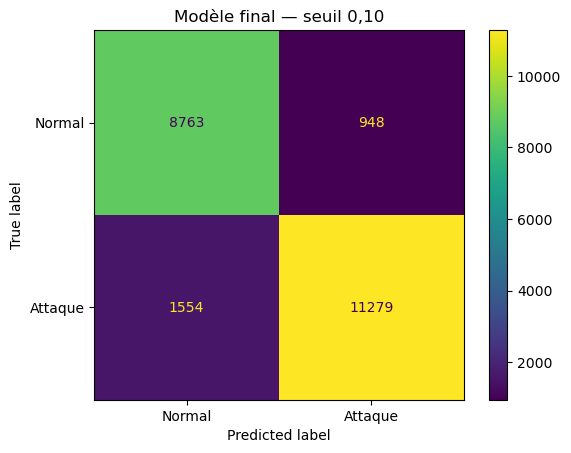

In [39]:
final_matrix = confusion_matrix(
    y_test,
    final_predictions
)

display = ConfusionMatrixDisplay(
    confusion_matrix=final_matrix,
    display_labels=["Normal", "Attaque"]
)

display.plot()
plt.title("Modèle final — seuil 0,10")
plt.show()

In [40]:
import joblib
from pathlib import Path

models_directory = Path("../models")
models_directory.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "pipeline": final_pipeline,
    "threshold": DECISION_THRESHOLD,
    "feature_names": list(X_train.columns)
}

model_path = models_directory / "intrusion_detector.joblib"

joblib.dump(model_bundle, model_path)

print("Modèle sauvegardé dans :", model_path)

Modèle sauvegardé dans : ..\models\intrusion_detector.joblib


In [41]:
import json

reports_directory = Path("../reports")
reports_directory.mkdir(parents=True, exist_ok=True)

metrics = {
    "threshold": DECISION_THRESHOLD,
    "accuracy": float(
        accuracy_score(y_test, final_predictions)
    ),
    "attack_precision": float(
        precision_score(y_test, final_predictions)
    ),
    "attack_recall": float(
        recall_score(y_test, final_predictions)
    ),
    "attack_f1_score": float(
        f1_score(y_test, final_predictions)
    ),
    "confusion_matrix": final_matrix.tolist()
}

with open(
    reports_directory / "final_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        metrics,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Résultats sauvegardés")

Résultats sauvegardés


In [42]:
sample_connection = X_test.iloc[[0]]

sample_connection.to_csv(
    "../data/sample_connection.csv",
    index=False
)

print("Connexion exemple sauvegardée")
print("Classe réelle :", y_test.iloc[0])

Connexion exemple sauvegardée
Classe réelle : 1


In [43]:
%%writefile ../src/predict.py

from pathlib import Path

import joblib
import pandas as pd


PROJECT_ROOT = Path(__file__).resolve().parents[1]
MODEL_PATH = PROJECT_ROOT / "models" / "intrusion_detector.joblib"
SAMPLE_PATH = PROJECT_ROOT / "data" / "sample_connection.csv"


def load_detector():
    if not MODEL_PATH.exists():
        raise FileNotFoundError(
            f"Modèle introuvable : {MODEL_PATH}"
        )

    return joblib.load(MODEL_PATH)


def predict_connections(data: pd.DataFrame) -> pd.DataFrame:
    bundle = load_detector()

    pipeline = bundle["pipeline"]
    threshold = bundle["threshold"]
    feature_names = bundle["feature_names"]

    missing_columns = [
        column
        for column in feature_names
        if column not in data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Colonnes manquantes : {missing_columns}"
        )

    data = data[feature_names]

    attack_probabilities = pipeline.predict_proba(data)[:, 1]

    predictions = (
        attack_probabilities >= threshold
    ).astype(int)

    result = data.copy()
    result["attack_probability"] = attack_probabilities
    result["prediction"] = [
        "Attaque" if prediction == 1 else "Normal"
        for prediction in predictions
    ]

    return result


if __name__ == "__main__":
    if not SAMPLE_PATH.exists():
        raise FileNotFoundError(
            f"Fichier exemple introuvable : {SAMPLE_PATH}"
        )

    sample = pd.read_csv(SAMPLE_PATH)
    result = predict_connections(sample)

    print(
        result[
            ["attack_probability", "prediction"]
        ].to_string(index=False)
    )

Overwriting ../src/predict.py


In [44]:
from pathlib import Path

print(
    Path(
        "../models/intrusion_detector.joblib"
    ).exists()
)

True


In [45]:
print("Classe réelle :", y_test.iloc[0])

Classe réelle : 1


In [46]:
normal_index = y_test[y_test == 0].index[0]
attack_index = y_test[y_test == 1].index[0]

normal_sample = X_test.loc[[normal_index]]
attack_sample = X_test.loc[[attack_index]]

normal_sample.to_csv("../data/normal_sample.csv", index=False)
attack_sample.to_csv("../data/attack_sample.csv", index=False)

print("Exemples créés")

Exemples créés


In [47]:
import json

attack_index = y_test[y_test == 1].index[0]

attack_example = X_test.loc[attack_index].to_dict()

print(json.dumps(attack_example, indent=4))

{
    "duration": 0,
    "protocol_type": "tcp",
    "service": "private",
    "flag": "REJ",
    "src_bytes": 0,
    "dst_bytes": 0,
    "land": 0,
    "wrong_fragment": 0,
    "urgent": 0,
    "hot": 0,
    "num_failed_logins": 0,
    "logged_in": 0,
    "num_compromised": 0,
    "root_shell": 0,
    "su_attempted": 0,
    "num_root": 0,
    "num_file_creations": 0,
    "num_shells": 0,
    "num_access_files": 0,
    "num_outbound_cmds": 0,
    "is_host_login": 0,
    "is_guest_login": 0,
    "count": 229,
    "srv_count": 10,
    "serror_rate": 0.0,
    "srv_serror_rate": 0.0,
    "rerror_rate": 1.0,
    "srv_rerror_rate": 1.0,
    "same_srv_rate": 0.04,
    "diff_srv_rate": 0.06,
    "srv_diff_host_rate": 0.0,
    "dst_host_count": 255,
    "dst_host_srv_count": 10,
    "dst_host_same_srv_rate": 0.04,
    "dst_host_diff_srv_rate": 0.06,
    "dst_host_same_src_port_rate": 0.0,
    "dst_host_srv_diff_host_rate": 0.0,
    "dst_host_serror_rate": 0.0,
    "dst_host_srv_serror_rate": 0.

In [49]:
normal_indices = y_test[y_test == 0].index[:5]
attack_indices = y_test[y_test == 1].index[:5]

selected_indices = list(normal_indices) + list(attack_indices)

batch_sample = X_test.loc[selected_indices].copy()

batch_sample.to_csv(
    "../data/batch_connections_v2.csv",
    index=False
)

print("Fichier créé :", batch_sample.shape)

Fichier créé : (10, 41)


In [50]:
train_df.shape
test_df.shape

(22544, 44)

In [51]:
import json
from pathlib import Path

normal_index = y_test[y_test == 0].index[0]
attack_index = y_test[y_test == 1].index[0]

normal_example = X_test.loc[normal_index].to_dict()
attack_example = X_test.loc[attack_index].to_dict()

examples = {
    "normal": normal_example,
    "attack": attack_example
}

output_path = Path("../data/examples.json")

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(
        examples,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Fichier créé :", output_path)
print("Classe normale :", y_test.loc[normal_index])
print("Classe attaque :", y_test.loc[attack_index])

Fichier créé : ..\data\examples.json
Classe normale : 0
Classe attaque : 1
